In [ ]:
# --------------------------------------------------------------------------
# 0. Libraries and Reproducibility
# --------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.stats import norm, skew
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
warnings.filterwarnings("ignore", category=Warning, module="sklearn.gaussian_process")
SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)


print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# --------------------------------------------------------------------------
# 1. Data
# --------------------------------------------------------------------------
X = np.load('..\Function_3_Data\Week_7_Data/F3_Week_7_inputs.npy')
y = np.load('..\Function_3_Data\Week_7_Data/F3_Week_7_outputs.npy')
n, d = X.shape
print(f"n = {n} observations, d = {d} input dimensions")

BOUNDS = np.array([[0.0, 1.0]] * d)


n = 21 observations, d = 3 input dimensions


Target statistics
min=-0.39893  max=-0.01230  mean=-0.08781  std=0.08010  skew=-2.624
ratio max(|y|)/min(|y|) = 32.4x -> heavily right-skewed magnitude, one clear outlier
Best observed point so far: X=[0.447851 0.552632 0.391512], y=-0.01230
Worst observed point: X=[0.15183663 0.43999062 0.99088187], y=-0.39893


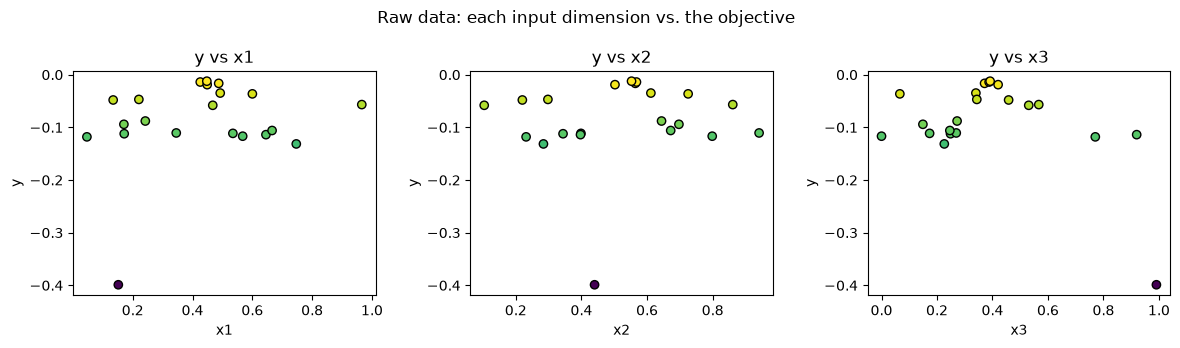

In [3]:
# --------------------------------------------------------------------------
# 2. Exploratory data analysis
# --------------------------------------------------------------------------
print("=" * 100)
print("Target statistics")
print("=" * 100)
print(f"min={y.min():.5f}  max={y.max():.5f}  mean={y.mean():.5f}  "
      f"std={y.std():.5f}  skew={skew(y):.3f}")
print(f"ratio max(|y|)/min(|y|) = {np.abs(y).max()/np.abs(y).min():.1f}x "
      "-> heavily right-skewed magnitude, one clear outlier")

best_idx_raw = np.argmax(y)
print(f"Best observed point so far: X={X[best_idx_raw]}, y={y[best_idx_raw]:.5f}")
print(f"Worst observed point: X={X[np.argmin(y)]}, y={y[np.argmin(y)]:.5f}")

fig, axes = plt.subplots(1, d, figsize=(4 * d, 3.5))
for i in range(d):
    axes[i].scatter(X[:, i], y, c=y, cmap="viridis", edgecolor="k")
    axes[i].set_xlabel(f"x{i+1}")
    axes[i].set_ylabel("y")
    axes[i].set_title(f"y vs x{i+1}")
fig.suptitle("Raw data: each input dimension vs. the objective")
fig.tight_layout()

Target Transformation
raw y   : skew=-2.624, range=0.3866
g=-log(-y): skew=0.280, range=3.4788
Current incumbent (best observed): x*=[0.447851 0.552632 0.391512], y*=-0.01230, g*=4.39776


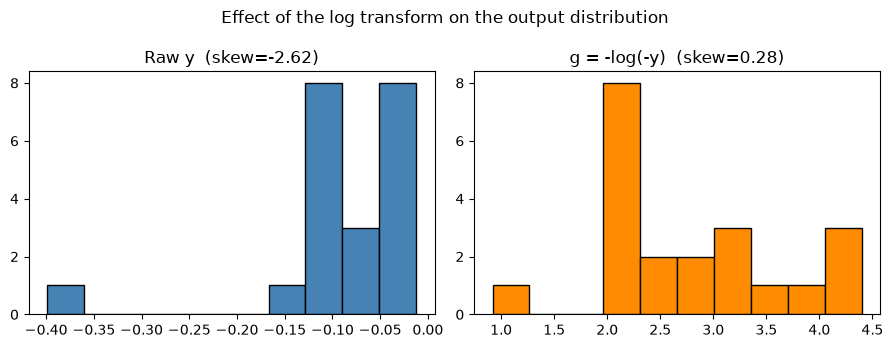

In [4]:
# --------------------------------------------------------------------------
# 3. Output transformation
# --------------------------------------------------------------------------
# WHY:
#   - y is strictly negative and spans ~32x in magnitude (-0.0123 to -0.399),
#     with one strong outlier (-0.399) and the rest clustered in [-0.13,-0.01].

#   - A GP assumes a roughly stationary, Gaussian-ish residual structure.
#   
#   - Since -y > 0 everywhere, log(-y) is well defined and compresses the
#     dynamic range.

#   - log is monotonic, so maximizing y  <=>  minimizing log(-y)
#                                        <=>  maximizing  g(x) = -log(-y(x))
#     We use g(x), so the whole pipeline can stay in "maximise" convention.
#   - We then standardise g (zero mean / unit variance) purely for numerical
#     conditioning of the GP hyperparameter optimisation. 

#   - sklearn's `normalize_y=True` does this internally and un-does it in predict()).

g = -np.log(-y)   # strictly positive -> maximise g <=> maximise y

print("=" * 100)
print("Target Transformation")
print("=" * 100)
print(f"raw y   : skew={skew(y):.3f}, range={y.max()-y.min():.4f}")
print(f"g=-log(-y): skew={skew(g):.3f}, range={g.max()-g.min():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(y, bins=10, color="steelblue", edgecolor="k")
axes[0].set_title(f"Raw y  (skew={skew(y):.2f})")
axes[1].hist(g, bins=10, color="darkorange", edgecolor="k")
axes[1].set_title(f"g = -log(-y)  (skew={skew(g):.2f})")
fig.suptitle("Effect of the log transform on the output distribution")
fig.tight_layout()

best_idx = np.argmax(g)      # same index as argmax(y), log is monotonic
assert best_idx == best_idx_raw
x_best, y_best, g_best = X[best_idx], y[best_idx], g[best_idx]
print(f"Current incumbent (best observed): x*={x_best}, y*={y_best:.5f}, g*={g_best:.5f}")


In [5]:
# --------------------------------------------------------------------------
# 4. Surrogate model: Gaussian Process - Matern(nu=2.5) ARD + WhiteKernel
# --------------------------------------------------------------------------

def make_gp(ard: bool, n_dims: int, seed: int) -> GaussianProcessRegressor:
    length_scale = np.ones(n_dims) if ard else 1.0
    kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=length_scale, length_scale_bounds=(1e-2, 1e2), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-8, 1e-1))
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,     # standardises g internally (mean 0, std 1)
        n_restarts_optimizer=20,  # marginal log-likelihood is non-convex
        random_state=seed,
    )

def loo_cv(ard: bool, X, g, seed):
    """Leave-one-out CV: refit on n-1 points, predict the held-out point.
    Returns RMSE and mean negative log predictive density (NLPD, lower=better)."""
    n = len(g)
    sq_err = np.zeros(n)
    nlpd = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        gp = make_gp(ard, X.shape[1], seed)
        gp.fit(X[mask], g[mask])
        mu, std = gp.predict(X[i:i+1], return_std=True)
        mu, std = mu[0], max(std[0], 1e-6)
        sq_err[i] = (mu - g[i]) ** 2
        nlpd[i] = 0.5 * np.log(2 * np.pi * std**2) + 0.5 * ((g[i] - mu) ** 2) / std**2
    return np.sqrt(sq_err.mean()), nlpd.mean()


print("=" * 100)
print("Model selection: isotropic vs ARD (leave-one-out CV)")
print("=" * 100)
results = {}
for ard in (False, True):
    rmse, nlpd = loo_cv(ard, X, g, SEED)
    gp_full = make_gp(ard, d, SEED).fit(X, g)
    lml = gp_full.log_marginal_likelihood(gp_full.kernel_.theta)
    results[ard] = (rmse, nlpd, lml, gp_full)
    tag = "ARD      " if ard else "Isotropic"
    print(f"{tag}: LOO-RMSE(g)={rmse:.4f}  LOO-NLPD={nlpd:.4f}  train LML={lml:.3f}")
    print(f"           fitted kernel: {gp_full.kernel_}")

use_ard = results[True][1] < results[False][1]   # lower LOO-NLPD wins
print(f"\n=> Selected model: {'ARD' if use_ard else 'Isotropic'} "
      "(lower leave-one-out NLPD; RMSE used as a tie-breaker)")

gp = results[use_ard][3]
kernel_params = gp.kernel_.get_params()
print("\nFitted hyperparameters of the chosen GP:")
print(gp.kernel_)

Model selection: isotropic vs ARD (leave-one-out CV)
Isotropic: LOO-RMSE(g)=0.6682  LOO-NLPD=0.8675  train LML=-22.853
           fitted kernel: 0.857**2 * Matern(length_scale=0.106, nu=2.5) + WhiteKernel(noise_level=1e-08)
ARD      : LOO-RMSE(g)=0.5504  LOO-NLPD=3.8970  train LML=-15.345
           fitted kernel: 0.979**2 * Matern(length_scale=[100, 1.13, 0.0743], nu=2.5) + WhiteKernel(noise_level=0.00586)

=> Selected model: Isotropic (lower leave-one-out NLPD; RMSE used as a tie-breaker)

Fitted hyperparameters of the chosen GP:
0.857**2 * Matern(length_scale=0.106, nu=2.5) + WhiteKernel(noise_level=1e-08)


In [6]:
# --------------------------------------------------------------------------
# 5. Acquisition function: Expected Improvement (EI)
# --------------------------------------------------------------------------
# We maximise g(x) (equivalent to maximising the true objective y(x)).
# EI(x) = E[max(g(x) - g_best - xi, 0)]
# Closed form for a GP posterior N(mu(x), sigma(x)^2):
#   z = (mu(x) - g_best - xi) / sigma(x)
#   EI(x) = (mu(x) - g_best - xi) * Phi(z) + sigma(x) * phi(z)   if sigma>0
#         = 0                                                    if sigma=0


XI = 0.02

def expected_improvement(Xcand, gp, g_best, xi=XI):
    mu, sigma = gp.predict(Xcand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    z = (mu - g_best - xi) / sigma
    ei = (mu - g_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

In [7]:
# --------------------------------------------------------------------------
# 6. Optimising the acquisition function -> next query point
# --------------------------------------------------------------------------
def propose_next(gp, g_best, bounds, n_restarts=50, seed=SEED):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    best_x, best_val = None, -np.inf

    def neg_ei(x):
        return -expected_improvement(x.reshape(1, -1), gp, g_best)[0]

    # multi-start L-BFGS-B: EI is multi-modal, so many random restarts
    # spread across the domain are used to avoid a poor local optimum.
    starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(n_restarts, dim))
    for x0 in starts:
        res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
        if -res.fun > best_val:
            best_val, best_x = -res.fun, res.x
    return best_x, best_val

x_next, ei_next = propose_next(gp, g_best, BOUNDS)
mu_next, std_next = gp.predict(x_next.reshape(1, -1), return_std=True)
print("=" * 100)
print("Next recommended query point (maximising EI)")
print("=" * 100)

print(f"x_next = {np.round(x_next, 6)}")
print(f"EI(x_next) = {ei_next:.5f}   posterior mean g = {mu_next[0]:.4f} "
      f"+/- {std_next[0]:.4f}")
print(f"(predicted y = -exp(-mu) -> point estimate y_hat = {-np.exp(-mu_next[0]):.4f}, "
      "for context only, EI already accounts for the uncertainty)")

Next recommended query point (maximising EI)
x_next = [0.459956 0.570861 0.426532]
EI(x_next) = 0.05708   posterior mean g = 4.2175 +/- 0.3361
(predicted y = -exp(-mu) -> point estimate y_hat = -0.0147, for context only, EI already accounts for the uncertainty)


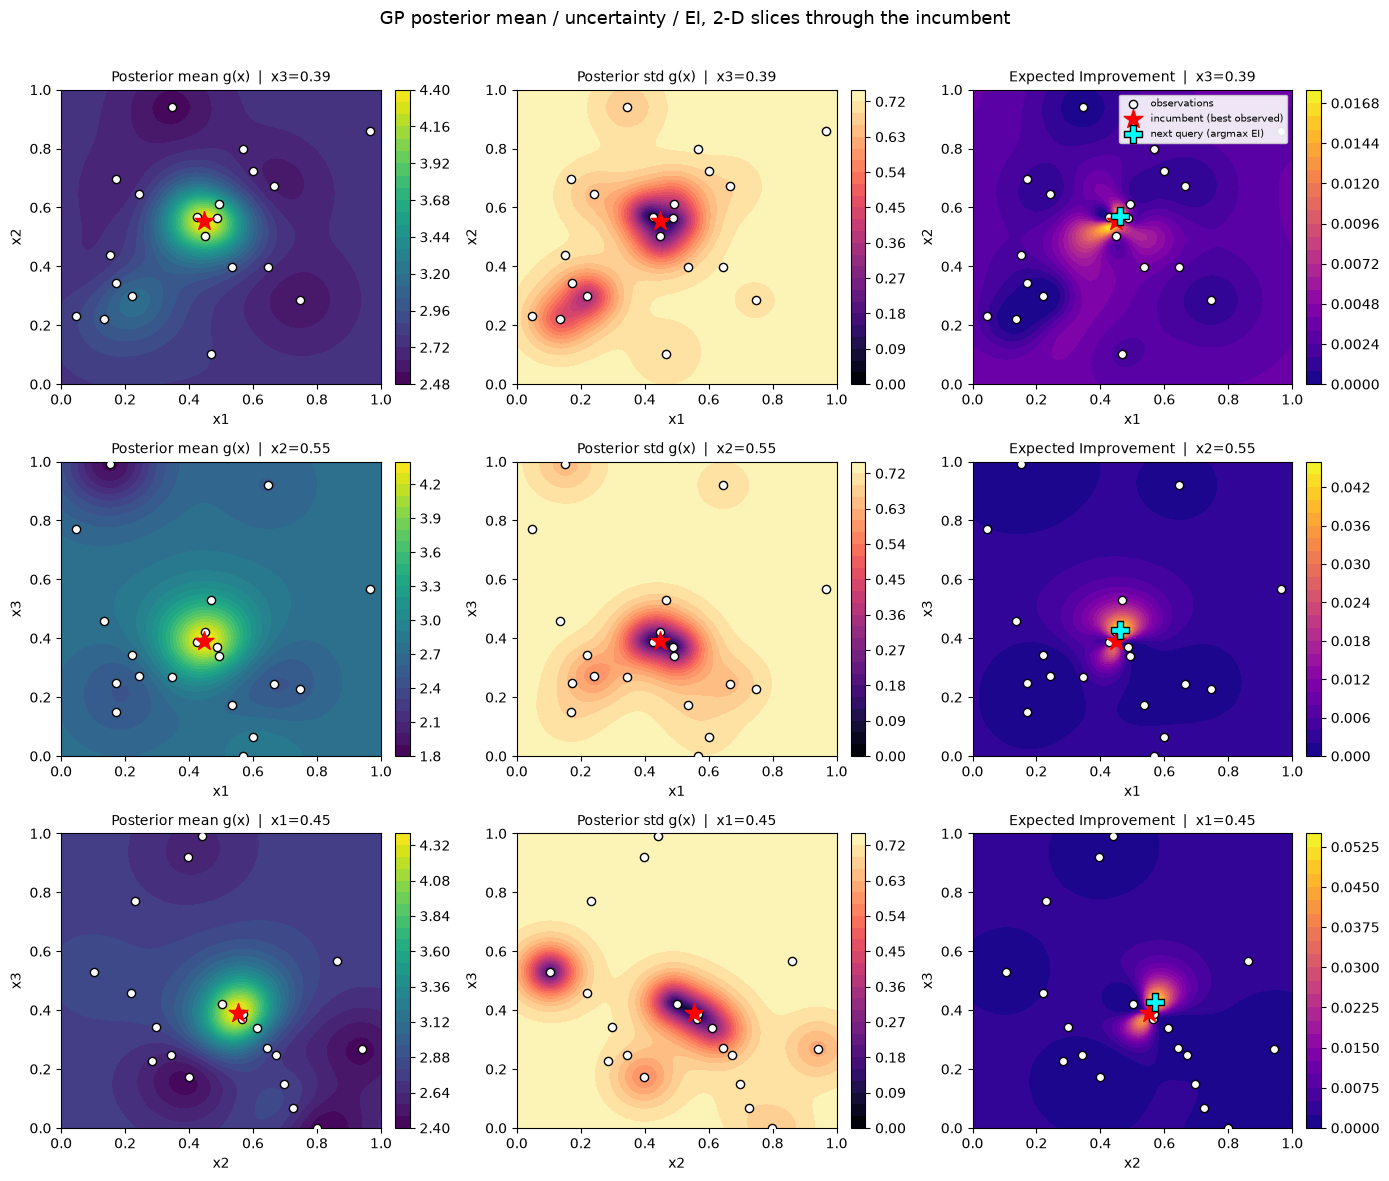

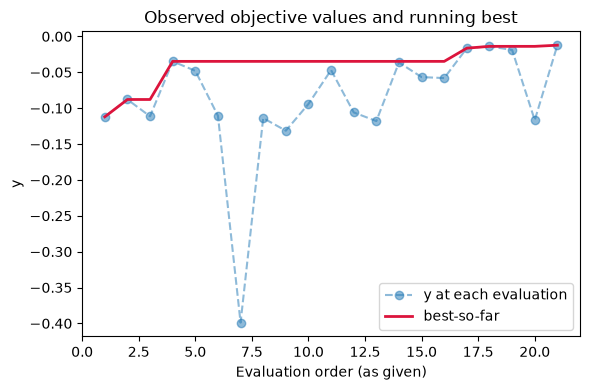

In [8]:
# --------------------------------------------------------------------------
# 7. Diagnostic / explanatory plots
# --------------------------------------------------------------------------
# The domain is 3-D, so we visualise 2-D slices through x_best (the current
# incumbent) for every pair of dimensions: posterior mean, posterior std,
# and EI, each as a contour/heat map with the 21 observations overlaid.

grid_n = 80
lin = np.linspace(0, 1, grid_n)

dim_names = ["x1", "x2", "x3"]
pairs = [(0, 1), (0, 2), (1, 2)]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for row, (i, j) in enumerate(pairs):
    k = [a for a in range(3) if a not in (i, j)][0]   # the fixed dimension
    fixed_val = x_best[k]

    A, B = np.meshgrid(lin, lin)
    grid = np.zeros((grid_n * grid_n, 3))
    grid[:, i] = A.ravel()
    grid[:, j] = B.ravel()
    grid[:, k] = fixed_val

    mu, std = gp.predict(grid, return_std=True)
    ei = expected_improvement(grid, gp, g_best)

    mu_grid = mu.reshape(grid_n, grid_n)
    std_grid = std.reshape(grid_n, grid_n)
    ei_grid = ei.reshape(grid_n, grid_n)

    for col, (Z, title, cmap) in enumerate([
        (mu_grid, f"Posterior mean g(x)  |  {dim_names[k]}={fixed_val:.2f}", "viridis"),
        (std_grid, f"Posterior std g(x)  |  {dim_names[k]}={fixed_val:.2f}", "magma"),
        (ei_grid, f"Expected Improvement  |  {dim_names[k]}={fixed_val:.2f}", "plasma"),
    ]):
        ax = axes[row, col]
        cf = ax.contourf(A, B, Z, levels=25, cmap=cmap)
        fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)
        ax.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=35, zorder=3,
                   label="observations")
        ax.scatter(x_best[i], x_best[j], marker="*", c="red", s=200, zorder=4,
                   label="incumbent (best observed)")
        if col == 2:
            ax.scatter(x_next[i], x_next[j], marker="P", c="cyan", s=180,
                       edgecolor="black", zorder=4, label="next query (argmax EI)")
        ax.set_xlabel(dim_names[i])
        ax.set_ylabel(dim_names[j])
        ax.set_title(title, fontsize=10)
        if row == 0 and col == 2:
            ax.legend(loc="upper right", fontsize=7, framealpha=0.9)

fig.suptitle("GP posterior mean / uncertainty / EI, 2-D slices through the incumbent",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])

# Best-observed-so-far trajectory, in the order the data was given
fig, ax = plt.subplots(figsize=(6, 4))
running_best = np.maximum.accumulate(y)
ax.plot(range(1, n + 1), y, "o--", alpha=0.5, label="y at each evaluation")
ax.plot(range(1, n + 1), running_best, "-", lw=2, color="crimson",
        label="best-so-far")
ax.set_xlabel("Evaluation order (as given)")
ax.set_ylabel("y")
ax.set_title("Observed objective values and running best")
ax.legend()
fig.tight_layout()